# Stress Testing a Market-Cap-Weighted MSFT/AAPL Portfolio
## A $-5\sigma$ shock to Apple, EWMA-updated covariances, and the ten-day loss

A \$1,000,000 portfolio holds Microsoft and Apple in proportion to their market
capitalisations on 09/01/2016. EWMA estimates of the mean vector and covariance matrix
of the daily log returns, built from five years of data (09/01/2011–09/01/2016), give
the one-day normal VaR, the ten-day VaR by the square-root-of-time rule and the
regulatory capital $3\times$ ten-day VaR. The system is then shocked: Apple's next
log return is set five standard deviations below its mean, Microsoft's five
*conditional* standard deviations below its conditional mean given Apple's, and the
EWMA mean and covariance are updated with the shock. Returns for days 2–10 are
simulated from the EWMA-updated normal model, $\hat M=50{,}000$ times, with the shares
held fixed, and the shocked ten-day losses are compared with the VaR and the capital
estimated before the shock.

**Notation.** Stock 1 is MSFT, stock 2 is AAPL. $X_{t+k\Delta}\in\mathbb R^2$ is the
vector of daily log returns over $[t+(k-1)\Delta,t+k\Delta]$ and $\theta_t=S_t\lambda_t$
the vector of dollar positions at $t$. The EWMA recursions are

$$\mu_{s+\Delta}=\lambda\mu_s+(1-\lambda)X_s,\qquad
\Sigma_{s+\Delta}=\theta\Sigma_s+(1-\theta)(X_s-\mu_s)(X_s-\mu_s)^{\top}.$$

If $X_{t+\Delta}\mid\mathcal F_t\sim N(\mu_{t+\Delta},\Sigma_{t+\Delta})$, the
linearized loss $L^{\mathrm{lin}}_{t+\Delta}=-\theta_t^{\top}X_{t+\Delta}$ is normal and

$$\mathrm{VaR}_\alpha\bigl(L^{\mathrm{lin}}_{t+\Delta}\bigr)=-\theta_t^{\top}\mu_{t+\Delta}
+\sqrt{\theta_t^{\top}\Sigma_{t+\Delta}\theta_t}\;\Phi^{-1}(\alpha).$$

Given $X_{t+\Delta,(2)}=x_{(2)}$, $X_{t+\Delta,(1)}$ is normal with mean
$\tilde\mu_{(1)}=\mu_{(1)}+\frac{\rho\,\sigma_{(1)}}{\sigma_{(2)}}\bigl(x_{(2)}-\mu_{(2)}\bigr)$
and variance $\tilde\sigma_{(1)}^2=\sigma_{(1)}^2(1-\rho^2)$. With the shares held
fixed, the $K$-day linearized loss is
$L^{\mathrm{lin}}_{t+K\Delta}=-\theta_t^{\top}\sum_{k=1}^{K}X_{t+k\Delta}$.

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.1.3
pandas      2.2.3
scipy       1.15.3
matplotlib  3.10.0


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| — | stocks: (1) and (2) | (1) MSFT, (2) AAPL |
| — | sample period (closing prices) | 09/01/2011 – 09/01/2016 |
| $\mathrm{cap}_i$ | market capitalisation on 09/01/2016, \$ billion | 448.77, 575.11 |
| $V$ | portfolio value at $t$ = 09/01/2016 | \$1,000,000 |
| $\alpha$ | VaR confidence level | 0.95 |
| $K$ | horizon, trading days | 10 |
| $\lambda,\ \theta$ | EWMA decay for the mean and the covariance | 0.97, 0.97 |
| $\mu,\ \Sigma$ | EWMA starting values | $0$, $0$ |
| — | size of the shocks | 5 (unconditional for AAPL, conditional for MSFT) |
| $\hat M$ | simulated paths | 50,000 |

The seed is fixed, so re-running the notebook reproduces every number exactly.

In [2]:
TICKERS   = ["MSFT", "AAPL"]          # (1) Microsoft, (2) Apple
FIRST_DAY = "2011-09-01"
LAST_DAY  = "2016-09-01"
CAP_BN    = np.array([448.77, 575.11])   # $ billion on 09/01/2016, same order as TICKERS
V_PORT    = 1_000_000.0
ALPHA     = 0.95
K_DAYS    = 10
LAM       = 0.97      # EWMA decay for the mean       (lambda)
THETA     = 0.97      # EWMA decay for the covariance (theta)
N_SHOCK   = 5.0       # size of each shock in (conditional) standard deviations
M_PATHS   = 50_000
SEED      = 731

DATA_FILE = Path("stock_prices.csv")
FIG1 = Path("stress_loss_distribution.png")
FIG2 = Path("stress_paths.png")

Z_ALPHA = norm.ppf(ALPHA)
SQRT_K = np.sqrt(K_DAYS)
usd = lambda v: ("-" if v < 0 else "") + r"\$" + f"{abs(v):,.0f}"   # dollar amount, safe in matplotlib text

# colour-blind-safe, print-friendly
C_SHOCK, C_BASE, C_LECT = "#e34948", "#2a78d6", "#eb6834"
C_INK, C_MUTE = "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"alpha = {ALPHA},  Phi^-1(alpha) = {Z_ALPHA:.6f},  K = {K_DAYS},  sqrt(K) = {SQRT_K:.6f},  "
      f"M = {M_PATHS:,},  seed = {SEED}")

alpha = 0.95,  Phi^-1(alpha) = 1.644854,  K = 10,  sqrt(K) = 3.162278,  M = 50,000,  seed = 731


---
## 3. Data

Daily **closing** prices from Yahoo Finance (`auto_adjust=False`, column `Close`), the
same convention as the earlier portfolio-VaR homework. Yahoo's `Close` is adjusted for
splits but not for dividends, so Apple's 7-for-1 split on 06/09/2014 does not create
an artificial return. Only trading days appear. The prices are cached in
`stock_prices.csv`, so every run after the first is offline and reproducible; the
file also holds the dividend-adjusted closes (`Adj Close`), used only for a robustness
check in section 11.

### Pseudocode — data acquisition

```
INPUT : tickers, first day d0, last day d1 (inclusive), cache file F
OUTPUT: one table, a row per trading day, a column of closing prices per ticker

 1  if F exists: read the table from F                  (no network access)
 2  else
 3        for each ticker: request the daily closes on [d0, d1] from Yahoo Finance
 4              ('end' is exclusive there, so ask for d1 + 1 day)
 5              if nothing comes back: stop and report it - never invent prices
 6        keep the trading days common to both tickers; sort by date; save to F
 7  check: first date = d0, last date = d1, no missing values, no repeated dates
 8  return the table
```

In [3]:
def download_prices(tickers, first, last):
    """Daily Close and Adj Close from Yahoo Finance on [first, last] (only used when the cache is missing)."""
    import yfinance as yf
    end = (pd.Timestamp(last) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    cols = []
    for t in tickers:
        df = yf.download(t, start=first, end=end, interval="1d", auto_adjust=False,
                         actions=False, progress=False, threads=False)
        if df is None or df.empty:
            raise RuntimeError(f"Yahoo Finance returned no data for {t}")
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
        cols += [df["Close"].astype(float).rename(t), df["Adj Close"].astype(float).rename(f"{t}_adj")]
    table = pd.concat(cols, axis=1, join="inner").sort_index()
    table.index.name = "Date"
    return table.loc[first:last, tickers + [f"{t}_adj" for t in tickers]]


if DATA_FILE.exists():
    raw = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)
    print(f"read cached prices from {DATA_FILE}")
else:
    raw = download_prices(TICKERS, FIRST_DAY, LAST_DAY)
    raw.to_csv(DATA_FILE, float_format="%.6f")
    print(f"downloaded prices from Yahoo Finance and saved them to {DATA_FILE}")

prices = raw[TICKERS]
assert str(prices.index[0].date()) == FIRST_DAY and str(prices.index[-1].date()) == LAST_DAY
assert raw.notna().all().all() and not raw.index.has_duplicates
assert raw.index.is_monotonic_increasing

print("\nFIRST FIVE OBSERVATIONS (closing prices, $)")
print(prices.head(5).to_string(float_format=lambda v: f"{v:10.2f}"))
print("\nLAST FIVE OBSERVATIONS (closing prices, $)")
print(prices.tail(5).to_string(float_format=lambda v: f"{v:10.2f}"))
N_OBS = len(prices)
print(f"\nnumber of observations: {N_OBS} trading days ({prices.index[0].date()} to {prices.index[-1].date()})")

read cached prices from stock_prices.csv

FIRST FIVE OBSERVATIONS (closing prices, $)
                 MSFT       AAPL
Date                            
2011-09-01      26.21      13.61
2011-09-02      25.80      13.36
2011-09-06      25.51      13.56
2011-09-07      26.00      13.71
2011-09-08      26.22      13.72

LAST FIVE OBSERVATIONS (closing prices, $)
                 MSFT       AAPL
Date                            
2016-08-26      58.03      26.74
2016-08-29      58.10      26.70
2016-08-30      57.89      26.50
2016-08-31      57.46      26.52
2016-09-01      57.59      26.68

number of observations: 1259 trading days (2011-09-01 to 2016-09-01)


---
## 4. Log returns, weights and dollar positions

The risk-factor changes are the daily log returns
$X_s=\bigl(\ln(S^{(1)}_s/S^{(1)}_{s-\Delta}),\ \ln(S^{(2)}_s/S^{(2)}_{s-\Delta})\bigr)$;
$N_{\text{obs}}$ prices give $N_{\text{obs}}-1$ returns, the last one dated $t$ =
09/01/2016. In a market-cap-weighted portfolio the dollar position in each stock is
proportional to its market cap, so

$$\omega_i=\frac{\lambda^{(i)}_tS^{(i)}_t}{V}=\frac{\mathrm{cap}_i}{\mathrm{cap}_1+\mathrm{cap}_2},
\qquad \theta_t=V\omega .$$

In [4]:
logret = np.log(prices).diff().dropna()
X_HIST = logret.to_numpy()              # shape (n, 2)
n_ret = len(logret)
print(f"{n_ret} daily log returns, {logret.index[0].date()} to {logret.index[-1].date()}\n")
summ = pd.DataFrame({
    "mean": logret.mean(), "sd (n-1)": logret.std(ddof=1),
    "min": logret.min(), "date of min": logret.idxmin().dt.date,
    "max": logret.max(), "date of max": logret.idxmax().dt.date,
})
print(summ.to_string(float_format=lambda v: f"{v: .5f}"))
print(f"\nfive-year sample correlation: {logret.corr().iloc[0, 1]:.4f}")
assert X_HIST.shape == (N_OBS - 1, 2)
assert np.abs(X_HIST).max() < 0.25, "a |log return| above 25% would point to an unadjusted split"

W = CAP_BN / CAP_BN.sum()
THETA_T = V_PORT * W                    # dollar positions theta_t = S_t lambda_t
SHARES = THETA_T / prices.iloc[-1].to_numpy()
print("\nWEIGHTS AND POSITIONS AT t = 09/01/2016")
print(pd.DataFrame({"cap ($bn)": CAP_BN, "weight": W, "$ position theta_t": THETA_T,
                    "close 09/01/2016": prices.iloc[-1].to_numpy(), "shares lambda_t": SHARES},
                   index=TICKERS).to_string(float_format=lambda v: f"{v:,.4f}"))
assert abs(W.sum() - 1) < 1e-12 and abs(THETA_T.sum() - V_PORT) < 1e-6

1258 daily log returns, 2011-09-02 to 2016-09-01

         mean  sd (n-1)      min date of min      max date of max
MSFT  0.00063   0.01495 -0.12103  2013-07-19  0.09941  2015-04-24
AAPL  0.00054   0.01679 -0.13188  2013-01-24  0.08502  2012-04-25

five-year sample correlation: 0.3294

WEIGHTS AND POSITIONS AT t = 09/01/2016
      cap ($bn)  weight  $ position theta_t  close 09/01/2016  shares lambda_t
MSFT   448.7700  0.4383        438,303.3168           57.5900       7,610.7539
AAPL   575.1100  0.5617        561,696.6832           26.6825      21,051.1257


---
## 5. Step 1 — EWMA mean vector and covariance matrix at $t$

Starting from $\mu=0$, $\Sigma=0$ before the first return (09/02/2011), the recursions
are run through every return up to and including $X_t$ (09/01/2016). The result,
$(\mu_{t+\Delta},\Sigma_{t+\Delta})$, is the forecast for the next day. The covariance
update uses the *old* mean, so the deviation is formed before $\mu$ is overwritten.
After $n$ updates the starting pair carries weight $0.97^{n}$, which is negligible.

### Pseudocode — EWMA update (used for the history and inside the simulation)

```
EWMA_UPDATE(mu, Sigma, x):                       one day's return x, old (mu, Sigma)
1  d <- x - mu                                   deviation from the OLD mean
2  mu    <- lambda * mu    + (1 - lambda) * x
3  Sigma <- theta  * Sigma + (1 - theta)  * d d^T
4  return mu, Sigma

ESTIMATION AT t:
1  mu <- (0, 0),  Sigma <- 2 x 2 zero matrix                    (allowed by the HW)
2  for each historical return x_s, in date order through 09/01/2016:
3        mu, Sigma <- EWMA_UPDATE(mu, Sigma, x_s)
4  return mu, Sigma                                    = mu_{t+Delta}, Sigma_{t+Delta}
```

In [5]:
def ewma_update(mu, Sig, x, lam=LAM, theta=THETA):
    """One EWMA step. Works for one (mu, Sigma) or for a stack of them (leading axis = paths)."""
    dev = x - mu
    mu_new = lam * mu + (1 - lam) * x
    Sig_new = theta * Sig + (1 - theta) * dev[..., :, None] * dev[..., None, :]
    return mu_new, Sig_new


mu, Sig = np.zeros(2), np.zeros((2, 2))
RHO_PATH = []
for x in X_HIST:
    mu, Sig = ewma_update(mu, Sig, x)
    RHO_PATH.append(Sig[0, 1] / np.sqrt(Sig[0, 0] * Sig[1, 1]) if Sig[0, 0] * Sig[1, 1] > 0 else np.nan)
MU_1, SIG_1 = mu, Sig                    # mu_{t+Delta}, Sigma_{t+Delta}
VOL_1 = np.sqrt(np.diag(SIG_1))
RHO_1 = SIG_1[0, 1] / (VOL_1[0] * VOL_1[1])

print("EWMA ESTIMATES AT t = 09/01/2016 (for the day t -> t + Delta), daily log returns\n")
print("mu_{t+Delta}   ", np.array2string(MU_1, formatter={"float_kind": lambda v: f"{v: .8f}"}))
print("Sigma_{t+Delta}")
print(np.array2string(SIG_1, formatter={"float_kind": lambda v: f"{v: .10f}"}))
print(f"\nvolatilities  sigma_(1) = {VOL_1[0]:.6f} (MSFT),  sigma_(2) = {VOL_1[1]:.6f} (AAPL)"
      f"   [annualised x sqrt(252): {VOL_1[0] * np.sqrt(252):.2%}, {VOL_1[1] * np.sqrt(252):.2%}]")
print(f"correlation   rho = {RHO_1:.6f}")
print(f"weight left on the starting values: 0.97^{n_ret} = {LAM ** n_ret:.1e}")
assert np.all(np.linalg.eigvalsh(SIG_1) > 0)

EWMA ESTIMATES AT t = 09/01/2016 (for the day t -> t + Delta), daily log returns

mu_{t+Delta}    [ 0.00125025  0.00106069]
Sigma_{t+Delta}
[[ 0.0001298971  0.0000330066]
 [ 0.0000330066  0.0001518517]]

volatilities  sigma_(1) = 0.011397 (MSFT),  sigma_(2) = 0.012323 (AAPL)   [annualised x sqrt(252): 18.09%, 19.56%]
correlation   rho = 0.235013
weight left on the starting values: 0.97^1258 = 2.3e-17


---
## 6. Step 2 — VaR before the shock

With $X_{t+\Delta}\mid\mathcal F_t\sim N(\mu_{t+\Delta},\Sigma_{t+\Delta})$,
$L^{\mathrm{lin}}_{t+\Delta}\sim N\bigl(-\theta_t^{\top}\mu_{t+\Delta},\
\theta_t^{\top}\Sigma_{t+\Delta}\theta_t\bigr)$. The square-root-of-time rule scales
the one-day VaR to $K$ days, and the regulatory capital is three times the $K$-day
VaR:

$$\widehat{\mathrm{VaR}}_\alpha\bigl(L^{\mathrm{lin}}_{t+K\Delta}\bigr)=\sqrt K\;\widehat{\mathrm{VaR}}_\alpha\bigl(L^{\mathrm{lin}}_{t+\Delta}\bigr),\qquad
\text{capital}=3\sqrt K\;\widehat{\mathrm{VaR}}_\alpha\bigl(L^{\mathrm{lin}}_{t+\Delta}\bigr).$$

In [6]:
M1 = -float(THETA_T @ MU_1)                       # mean of the one-day linearized loss
S1 = float(np.sqrt(THETA_T @ SIG_1 @ THETA_T))    # its standard deviation
VAR_1 = M1 + S1 * Z_ALPHA
VAR_K = SQRT_K * VAR_1
CAPITAL = 3 * VAR_K
print("ONE-DAY LINEARIZED LOSS  L ~ N(m, s^2)")
print(f"  m = -theta' mu        = {M1:>12,.2f}")
print(f"  s = sqrt(theta' S theta) = {S1:>9,.2f}")
print(f"\n  VaR_0.95(L_t+D)             = m + s * {Z_ALPHA:.6f} = {VAR_1:>12,.2f}")
print(f"  10-day VaR, sqrt(10) * VaR  = {VAR_K:>12,.2f}")
print(f"  regulatory capital, 3 x that = {CAPITAL:>11,.2f}")

ONE-DAY LINEARIZED LOSS  L ~ N(m, s^2)
  m = -theta' mu        =    -1,143.78
  s = sqrt(theta' S theta) =  9,440.14

  VaR_0.95(L_t+D)             = m + s * 1.644854 =    14,383.87
  10-day VaR, sqrt(10) * VaR  =    45,485.79
  regulatory capital, 3 x that =  136,457.38


---
## 7. Step 3 — the shock and the EWMA update

The shock is deterministic: Apple's return is set to
$x_{(2)}=\mu_{t+\Delta,(2)}-5\sigma_{t+\Delta,(2)}$, and Microsoft's to
$x_{(1)}=\tilde\mu_{t+\Delta,(1)}-5\tilde\sigma_{t+\Delta,(1)}$, five *conditional*
standard deviations below its conditional mean given $x_{(2)}$. Substituting
$x_{(2)}-\mu_{(2)}=-5\sigma_{(2)}$,

$$x_{(1)}=\mu_{(1)}-5\sigma_{(1)}\Bigl(\rho+\sqrt{1-\rho^2}\Bigr),$$

and $\rho+\sqrt{1-\rho^2}\ge1$ for $0\le\rho\le1$, so Microsoft's shock is at least as
many *unconditional* standard deviations as Apple's. The shocked return
$x=(x_{(1)},x_{(2)})$ is the same on every path, so day 1 contributes the fixed loss
$-\theta_t^{\top}x$, and $(\mu_{t+2\Delta},\Sigma_{t+2\Delta})$ follow from one EWMA
update with $x$.

In [7]:
X2 = MU_1[1] - N_SHOCK * VOL_1[1]
MU_TILDE = MU_1[0] + RHO_1 * VOL_1[0] / VOL_1[1] * (X2 - MU_1[1])
SD_TILDE = VOL_1[0] * np.sqrt(1 - RHO_1 ** 2)
X1 = MU_TILDE - N_SHOCK * SD_TILDE
X_SHOCK = np.array([X1, X2])
LOSS_DAY1 = -float(THETA_T @ X_SHOCK)

MU_2, SIG_2 = ewma_update(MU_1, SIG_1, X_SHOCK)
VOL_2 = np.sqrt(np.diag(SIG_2))
RHO_2 = SIG_2[0, 1] / (VOL_2[0] * VOL_2[1])

print("THE SHOCK (day 1, the same on every path)")
print(f"  x_(2) = mu_(2) - 5 sigma_(2)          = {MU_1[1]:.6f} - 5 x {VOL_1[1]:.6f} = {X2:.6f}"
      f"   ({np.expm1(X2):.2%} price change)")
print(f"  conditional mean of X_(1) given x_(2) = {MU_TILDE:.6f}")
print(f"  conditional sd   of X_(1)             = {SD_TILDE:.6f}")
print(f"  x_(1) = mu~ - 5 sigma~                = {X1:.6f}   ({np.expm1(X1):.2%} price change)")
print(f"  x_(1) in unconditional sd of MSFT     = {(X1 - MU_1[0]) / VOL_1[0]:.4f}"
      f"   (= -5 (rho + sqrt(1 - rho^2)) = {-5 * (RHO_1 + np.sqrt(1 - RHO_1 ** 2)):.4f})")
print(f"  day-1 loss  -theta' x                 = {LOSS_DAY1:,.2f}"
      f"   ({LOSS_DAY1 / VAR_1:.2f} one-day VaRs, {LOSS_DAY1 / VAR_K:.1%} of the 10-day VaR)")

print("\nEWMA UPDATE WITH THE SHOCK:  t + Delta  ->  t + 2 Delta")
print(f"  {'':<22}{'before':>14}{'after':>14}")
print(f"  {'mu_(1)  (MSFT)':<22}{MU_1[0]:>14.6f}{MU_2[0]:>14.6f}")
print(f"  {'mu_(2)  (AAPL)':<22}{MU_1[1]:>14.6f}{MU_2[1]:>14.6f}")
print(f"  {'sigma_(1)  (MSFT)':<22}{VOL_1[0]:>14.6f}{VOL_2[0]:>14.6f}")
print(f"  {'sigma_(2)  (AAPL)':<22}{VOL_1[1]:>14.6f}{VOL_2[1]:>14.6f}")
print(f"  {'rho':<22}{RHO_1:>14.6f}{RHO_2:>14.6f}")
print(f"  {'1-day mean loss':<22}{-THETA_T @ MU_1:>14,.2f}{-THETA_T @ MU_2:>14,.2f}")
print(f"  {'1-day normal VaR':<22}{VAR_1:>14,.2f}{-THETA_T @ MU_2 + np.sqrt(THETA_T @ SIG_2 @ THETA_T) * Z_ALPHA:>14,.2f}")

THE SHOCK (day 1, the same on every path)
  x_(2) = mu_(2) - 5 sigma_(2)          = 0.001061 - 5 x 0.012323 = -0.060553   (-5.88% price change)
  conditional mean of X_(1) given x_(2) = -0.012142
  conditional sd   of X_(1)             = 0.011078
  x_(1) = mu~ - 5 sigma~                = -0.067532   (-6.53% price change)
  x_(1) in unconditional sd of MSFT     = -6.0350   (= -5 (rho + sqrt(1 - rho^2)) = -6.0350)
  day-1 loss  -theta' x                 = 63,612.29   (4.42 one-day VaRs, 139.9% of the 10-day VaR)

EWMA UPDATE WITH THE SHOCK:  t + Delta  ->  t + 2 Delta
                                before         after
  mu_(1)  (MSFT)              0.001250     -0.000813
  mu_(2)  (AAPL)              0.001061     -0.000788
  sigma_(1)  (MSFT)           0.011397      0.016369
  sigma_(2)  (AAPL)           0.012323      0.016161
  rho                         0.235013      0.601639
  1-day mean loss            -1,143.78        798.91
  1-day normal VaR           14,383.87     24,762.07


---
## 8. Steps 4–5 — simulating days 2 to $K$

On each path, $X_{t+k\Delta}\sim N(\mu_{t+k\Delta},\Sigma_{t+k\Delta})$ for
$k=2,\dots,K$, drawn as $\mu+Cz$ with $CC^{\top}=\Sigma$ (Cholesky) and $z$ two
independent standard normals, and the mean and covariance are updated by EWMA after
every day except the last. Because the EWMA state depends on the path, every path has
its own $(\mu,\Sigma)$ from day 3 on. All $\hat M$ paths are advanced together; the
$2\times2$ Cholesky factor is written out explicitly,
$C=\begin{pmatrix}a&0\\b&c\end{pmatrix}$ with $a=\sqrt{\Sigma_{11}}$,
$b=\Sigma_{21}/a$, $c=\sqrt{\Sigma_{22}-b^2}$. The shares are held fixed, so the loss is
$\ell_m=-\theta_t^{\top}\sum_{k=1}^{K}X^m_{t+k\Delta}$.

The same routine also runs two comparison experiments (section 11), on the same
random numbers: the **lecture's version** of step 3, where Microsoft's day-1 return is
*drawn* from its conditional distribution instead of being set to $-5$ conditional
standard deviations, and **no shock**, where day 1 is drawn from
$N(\mu_{t+\Delta},\Sigma_{t+\Delta})$ like every other day.

### Pseudocode — the stress test

```
INPUT : theta_t, mu_{t+D}, Sigma_{t+D}, shock x = (x1, x2), lambda, theta, K, M, seed
OUTPUT: shocked K-day losses l_1 ... l_M; (a) mean, (b) VaR, (c), (d) exceedance %

 1  z <- M x K x 2 independent N(0,1) draws (fixed seed)
 2  for every path m = 1 ... M  (all paths at once):
 3        sum_x <- x                                               day 1: the shock
 4        (mu, Sigma) <- EWMA_UPDATE(mu_{t+D}, Sigma_{t+D}, x)     = (mu_{t+2D}, Sigma_{t+2D})
 5        for k = 2 ... K:
 6              a <- sqrt(Sigma_11);  b <- Sigma_21 / a;  c <- sqrt(Sigma_22 - b^2)
 7              X <- mu + (a z1,  b z1 + c z2)        with (z1, z2) = z[m, k]
 8              sum_x <- sum_x + X
 9              if k < K: (mu, Sigma) <- EWMA_UPDATE(mu, Sigma, X)
10        l_m <- - theta_t . sum_x                            shares held fixed over K days
11  (a) mean of l_1 ... l_M
12  (b) VaR = l_(ceil(M alpha))  (sort ascending)
13  (c) 100/M x #{m : l_m > sqrt(K) VaR_alpha(L_{t+D})}
14  (d) 100/M x #{m : l_m > 3 sqrt(K) VaR_alpha(L_{t+D})}
```

In [8]:
def simulate(day1, z, mu1=MU_1, Sig1=SIG_1, theta_t=THETA_T, K=K_DAYS):
    """K-day paths of the EWMA-normal model. day1: (M, 2) array of day-1 returns.
    Returns the K-day losses, the cumulative losses after each day and the EWMA correlation
    in force on each day (rho_{t+k Delta}, k = 1..K)."""
    M = len(day1)
    mu = np.broadcast_to(mu1, (M, 2)).copy()
    Sig = np.broadcast_to(Sig1, (M, 2, 2)).copy()
    cum = np.empty((M, K)); rho = np.empty((M, K))
    rho[:, 0] = Sig1[0, 1] / np.sqrt(Sig1[0, 0] * Sig1[1, 1])
    sum_x = day1.copy()
    cum[:, 0] = -sum_x @ theta_t
    mu, Sig = ewma_update(mu, Sig, day1)
    for k in range(1, K):                                    # days 2..K (0-based index k)
        a = np.sqrt(Sig[:, 0, 0]); b = Sig[:, 1, 0] / a; c = np.sqrt(Sig[:, 1, 1] - b ** 2)
        rho[:, k] = b / np.sqrt(Sig[:, 1, 1])
        x = mu + np.column_stack([a * z[:, k, 0], b * z[:, k, 0] + c * z[:, k, 1]])
        sum_x += x
        cum[:, k] = -sum_x @ theta_t
        if k < K - 1:                                        # no update needed after day K
            mu, Sig = ewma_update(mu, Sig, x)
    return cum[:, -1], cum, rho


def emp_var(losses, alpha=ALPHA):
    """VaR of the empirical distribution: the ceil(n alpha)-th smallest loss."""
    j = int(np.ceil(len(losses) * alpha))
    return float(np.sort(losses)[j - 1]), j


def quantile_band(losses, alpha=ALPHA, z=1.959964):
    """Distribution-free ~95% band for the true alpha-quantile from order statistics."""
    l = np.sort(losses); n = len(l); half = z * np.sqrt(n * alpha * (1 - alpha))
    return float(l[int(np.floor(n * alpha - half)) - 1]), float(l[int(np.ceil(n * alpha + half)) - 1])


rng = np.random.default_rng(SEED)
ZS = rng.standard_normal((M_PATHS, K_DAYS, 2))     # the same draws drive all three experiments

day1_hw = np.tile(X_SHOCK, (M_PATHS, 1))
L_HW, CUM_HW, RHO_HW = simulate(day1_hw, ZS)
print(f"simulated {M_PATHS:,} shocked {K_DAYS}-day paths;  every Sigma stayed positive definite: "
      f"{bool(np.isfinite(L_HW).all())}")

simulated 50,000 shocked 10-day paths;  every Sigma stayed positive definite: True


---
## 9. Results (a)–(d)

The frequencies are $\frac{100}{\hat M}\times$ the number of exceedances. The
Monte-Carlo precision is shown next to each number: a $\pm1.96$ standard-error interval
for the mean and the frequencies, and the distribution-free order-statistic band for
the VaR.

In [9]:
def results(L):
    var_, j = emp_var(L)
    n_var, n_cap = int((L > VAR_K).sum()), int((L > CAPITAL).sum())
    return dict(mean=float(L.mean()), se=float(L.std(ddof=1) / np.sqrt(len(L))), var=var_, j=j,
                band=quantile_band(L), n_var=n_var, n_cap=n_cap,
                f_var=100 * n_var / len(L), f_cap=100 * n_cap / len(L))


R_HW = results(L_HW)
se_f = lambda f: 100 * np.sqrt((f / 100) * (1 - f / 100) / M_PATHS)
print(f"SHOCKED {K_DAYS}-DAY LINEARIZED LOSSES,  M = {M_PATHS:,} paths\n")
print(f"(a) average {K_DAYS}-day loss         = {R_HW['mean']:>12,.2f}    +/- {1.96 * R_HW['se']:,.2f}")
print(f"(b) {K_DAYS}-day VaR_0.95  (l_({R_HW['j']:,}))  = {R_HW['var']:>12,.2f}"
      f"    order-statistic band [{R_HW['band'][0]:,.0f}, {R_HW['band'][1]:,.0f}]")
print(f"(c) % of losses > sqrt(10) VaR = {VAR_K:,.2f}:   {R_HW['f_var']:7.3f} %   "
      f"({R_HW['n_var']:,} of {M_PATHS:,};  +/- {1.96 * se_f(R_HW['f_var']):.3f})")
print(f"(d) % of losses > capital      = {CAPITAL:,.2f}:  {R_HW['f_cap']:7.3f} %   "
      f"({R_HW['n_cap']:,} of {M_PATHS:,};  +/- {1.96 * se_f(R_HW['f_cap']):.3f})")
print(f"\nfor reference: a correct 10-day VaR is exceeded 5% of the time; the day-1 shock alone costs "
      f"{LOSS_DAY1:,.2f}")
print(f"shocked 10-day VaR / pre-shock 10-day VaR = {R_HW['var'] / VAR_K:.3f}")
q = np.percentile(L_HW, [1, 5, 25, 50, 75, 95, 99])
print("percentiles of the shocked loss (1, 5, 25, 50, 75, 95, 99): "
      + ", ".join(f"{v:,.0f}" for v in q))

SHOCKED 10-DAY LINEARIZED LOSSES,  M = 50,000 paths

(a) average 10-day loss         =    70,970.47    +/- 435.21
(b) 10-day VaR_0.95  (l_(47,500))  =   152,352.06    order-statistic band [151,325, 153,416]
(c) % of losses > sqrt(10) VaR = 45,485.79:    69.866 %   (34,933 of 50,000;  +/- 0.402)
(d) % of losses > capital      = 136,457.38:    9.100 %   (4,550 of 50,000;  +/- 0.252)

for reference: a correct 10-day VaR is exceeded 5% of the time; the day-1 shock alone costs 63,612.29
shocked 10-day VaR / pre-shock 10-day VaR = 3.349
percentiles of the shocked loss (1, 5, 25, 50, 75, 95, 99): -45,558, -10,913, 37,840, 71,233, 103,802, 152,353, 188,276


### Check on (a): the expected loss in closed form

On every path $E[\mu_{t+(k+1)\Delta}]=\lambda E[\mu_{t+k\Delta}]+(1-\lambda)E[X_{t+k\Delta}]
=E[\mu_{t+k\Delta}]$, because $E[X_{t+k\Delta}\mid\mathcal F_{t+(k-1)\Delta}]=\mu_{t+k\Delta}$.
So the expected EWMA mean stays at $\mu_{t+2\Delta}$ for all $k\ge2$, and

$$E\bigl[L^{\mathrm{lin}}_{t+K\Delta}\bigr]=-\theta_t^{\top}x-(K-1)\,\theta_t^{\top}\mu_{t+2\Delta}.$$

In [10]:
EL_HW = LOSS_DAY1 - (K_DAYS - 1) * float(THETA_T @ MU_2)
print(f"closed form   E[L] = {LOSS_DAY1:,.2f} + {K_DAYS - 1} x {-THETA_T @ MU_2:,.2f} = {EL_HW:,.2f}")
print(f"simulated mean     = {R_HW['mean']:,.2f}   (difference {R_HW['mean'] - EL_HW:+,.2f}, "
      f"{(R_HW['mean'] - EL_HW) / R_HW['se']:+.2f} standard errors)")

closed form   E[L] = 63,612.29 + 9 x 798.91 = 70,802.45
simulated mean     = 70,970.47   (difference +168.02, +0.76 standard errors)


---
## 10. Where the shocked loss comes from

The day-1 loss is fixed; the remaining nine days add a random amount whose mean is
$-(K-1)\theta_t^{\top}\mu_{t+2\Delta}$ (the shock drags the EWMA mean down) and whose
spread is set by the post-shock covariance, in which both volatilities and the
correlation have jumped.

In [11]:
rest = L_HW - LOSS_DAY1
print(f"day 1 (shock)            {LOSS_DAY1:>12,.2f}   fixed")
print(f"days 2-{K_DAYS}, mean          {rest.mean():>12,.2f}   (of which the EWMA mean drift: "
      f"{-(K_DAYS - 1) * THETA_T @ MU_2:,.2f})")
print(f"days 2-{K_DAYS}, st. deviation {rest.std(ddof=1):>12,.2f}")
print(f"days 2-{K_DAYS}, 95th pct      {np.percentile(rest, 95):>12,.2f}")
print(f"\nsd of 9 days at the PRE-shock covariance, sqrt(9) s = {3 * S1:,.2f}")
print(f"sd of 9 days at the POST-shock covariance, no further updates = "
      f"{3 * np.sqrt(THETA_T @ SIG_2 @ THETA_T):,.2f}")
med_rho = np.median(RHO_HW, axis=0)
print("\nmedian EWMA correlation in force on day k = 1..10 (shocked):",
      ", ".join(f"{v:.3f}" for v in med_rho))

day 1 (shock)               63,612.29   fixed
days 2-10, mean              7,358.18   (of which the EWMA mean drift: 7,190.16)
days 2-10, st. deviation    49,651.51
days 2-10, 95th pct         88,740.26

sd of 9 days at the PRE-shock covariance, sqrt(9) s = 28,320.42
sd of 9 days at the POST-shock covariance, no further updates = 43,705.71



median EWMA correlation in force on day k = 1..10 (shocked): 0.235, 0.602, 0.602, 0.602, 0.602, 0.602, 0.603, 0.603, 0.603, 0.604


---
## 11. Comparisons

* **No shock:** day 1 is drawn like every other day, so the losses show what the
  model expects without stress; their mean should be close to $-K\theta_t^{\top}\mu_{t+\Delta}$
  and roughly 5% of them should exceed the square-root-of-time VaR.
* **Lecture version of step 3:** Microsoft's day-1 return is drawn from its conditional
  distribution, $X_{(1)}=\tilde\mu_{(1)}+\tilde\sigma_{(1)}Z$, instead of being set to
  $\tilde\mu_{(1)}-5\tilde\sigma_{(1)}$. The sheet says its version is "(with high
  probability) more stressful".
* **Lecture slides 42–45** ran this example (same stocks, caps, window and
  parameters, 100,000 paths, lecture version of step 3); their numbers are printed for
  comparison.
* **Dividend-adjusted prices:** the pre-shock numbers recomputed from `Adj Close`.

In [12]:
day1_base = MU_1 + np.column_stack([np.sqrt(SIG_1[0, 0]) * ZS[:, 0, 0],
                                    SIG_1[1, 0] / np.sqrt(SIG_1[0, 0]) * ZS[:, 0, 0]
                                    + np.sqrt(SIG_1[1, 1] - SIG_1[1, 0] ** 2 / SIG_1[0, 0]) * ZS[:, 0, 1]])
L_BASE, CUM_BASE, RHO_BASE = simulate(day1_base, ZS)
day1_lect = np.column_stack([MU_TILDE + SD_TILDE * ZS[:, 0, 0], np.full(M_PATHS, X2)])
L_LECT, CUM_LECT, RHO_LECT = simulate(day1_lect, ZS)
R_BASE, R_LECT = results(L_BASE), results(L_LECT)

LECTURE = dict(var1=14_384, vark=45_486, cap=136_457, rho=0.235,
               shock=dict(mean=39_823, var=105_405, f_var=43.91, f_cap=0.897),
               base=dict(mean=-11_590, var=44_102, f_var=4.62, f_cap=0.007))

print(f"{K_DAYS}-DAY LOSSES, M = {M_PATHS:,} paths, same random numbers\n")
print(f"  {'':<30}{'HW shock':>14}{'lecture shock':>16}{'no shock':>14}")
print(f"  {'(a) average loss':<30}{R_HW['mean']:>14,.2f}{R_LECT['mean']:>16,.2f}{R_BASE['mean']:>14,.2f}")
print(f"  {'(b) 10-day VaR_0.95':<30}{R_HW['var']:>14,.2f}{R_LECT['var']:>16,.2f}{R_BASE['var']:>14,.2f}")
print(f"  {'(c) % > sqrt(10) VaR':<30}{R_HW['f_var']:>14.3f}{R_LECT['f_var']:>16.3f}{R_BASE['f_var']:>14.3f}")
print(f"  {'(d) % > capital':<30}{R_HW['f_cap']:>14.3f}{R_LECT['f_cap']:>16.3f}{R_BASE['f_cap']:>14.3f}")
print(f"  {'day-1 loss (mean)':<30}{LOSS_DAY1:>14,.2f}{-(day1_lect @ THETA_T).mean():>16,.2f}"
      f"{-(day1_base @ THETA_T).mean():>14,.2f}")
EL_BASE = -K_DAYS * float(THETA_T @ MU_1)
print(f"\nno shock: closed-form mean -K theta' mu = {EL_BASE:,.2f}")
EL_LECT = -float(THETA_T @ np.array([MU_TILDE, X2])) - (K_DAYS - 1) * float(
    THETA_T @ (LAM * MU_1 + (1 - LAM) * np.array([MU_TILDE, X2])))
print(f"lecture shock: closed-form mean = {EL_LECT:,.2f}")
print(f"paths on which the HW loss exceeds the lecture-version loss: {np.mean(L_HW > L_LECT):.2%}")
print(f"P(conditional draw of X_(1) lies above mu~ - 5 sd~) = Phi(5) = {norm.cdf(5):.7f}")

print("\nLECTURE SLIDES 42-45 (their data download, 100,000 paths, lecture shock)")
print(f"  rho {LECTURE['rho']},  VaR_1 {LECTURE['var1']:,},  sqrt(10) VaR {LECTURE['vark']:,},  capital {LECTURE['cap']:,}")
for nm in ("shock", "base"):
    d = LECTURE[nm]
    print(f"  {nm:<6} mean {d['mean']:>9,}   VaR {d['var']:>9,}   % > VaR {d['f_var']:>6}   % > capital {d['f_cap']}")
print(f"  ours:  rho {RHO_1:.3f},  VaR_1 {VAR_1:,.0f},  sqrt(10) VaR {VAR_K:,.0f},  capital {CAPITAL:,.0f}")
# our numbers vs the slides, in units of the combined Monte-Carlo standard error (50,000 + 100,000 paths)
print("  difference (ours - slides) / combined standard error:")
for nm, L, R in (("shock", L_LECT, R_LECT), ("base", L_BASE, R_BASE)):
    d = LECTURE[nm]; sd = L.std(ddof=1)
    z_mean = (R["mean"] - d["mean"]) / (sd * np.sqrt(1 / M_PATHS + 1 / 100_000))
    zf = lambda f_ours, f_lect: (f_ours - f_lect) / (100 * np.sqrt((f_ours / 100) * (1 - f_ours / 100) / M_PATHS
                                                                + (f_lect / 100) * (1 - f_lect / 100) / 100_000))
    se_q = (R["band"][1] - R["band"][0]) / (2 * 1.959964)          # s.e. of our VaR, from the band
    z_var = (R["var"] - d["var"]) / (se_q * np.sqrt(1 + M_PATHS / 100_000))
    print(f"    {nm:<6} mean {z_mean:+.2f}   % > VaR {zf(R['f_var'], d['f_var']):+.2f}   "
          f"% > capital {zf(R['f_cap'], d['f_cap']):+.2f}   VaR {z_var:+.2f}")

adj = raw[[f"{t}_adj" for t in TICKERS]].to_numpy()
mu_a, Sig_a = np.zeros(2), np.zeros((2, 2))
for x in np.diff(np.log(adj), axis=0):
    mu_a, Sig_a = ewma_update(mu_a, Sig_a, x)
var1_a = -THETA_T @ mu_a + np.sqrt(THETA_T @ Sig_a @ THETA_T) * Z_ALPHA
print(f"\nDIVIDEND-ADJUSTED PRICES: rho {Sig_a[0, 1] / np.sqrt(Sig_a[0, 0] * Sig_a[1, 1]):.4f}, "
      f"VaR_1 {var1_a:,.2f} (Close: {VAR_1:,.2f}), sqrt(10) VaR {SQRT_K * var1_a:,.2f}, "
      f"capital {3 * SQRT_K * var1_a:,.2f}")

10-DAY LOSSES, M = 50,000 paths, same random numbers

                                      HW shock   lecture shock      no shock
  (a) average loss                   70,970.47       40,035.76    -11,343.42
  (b) 10-day VaR_0.95               152,352.06      106,265.10     44,722.66
  (c) % > sqrt(10) VaR                  69.866          44.410         4.750
  (d) % > capital                        9.100           0.964         0.002


  day-1 loss (mean)                  63,612.29       39,314.91     -1,138.61

no shock: closed-form mean -K theta' mu = -11,437.76
lecture shock: closed-form mean = 39,969.79
paths on which the HW loss exceeds the lecture-version loss: 96.64%
P(conditional draw of X_(1) lies above mu~ - 5 sd~) = Phi(5) = 0.9999997

LECTURE SLIDES 42-45 (their data download, 100,000 paths, lecture shock)
  rho 0.235,  VaR_1 14,384,  sqrt(10) VaR 45,486,  capital 136,457
  shock  mean    39,823   VaR   105,405   % > VaR  43.91   % > capital 0.897
  base   mean   -11,590   VaR    44,102   % > VaR   4.62   % > capital 0.007
  ours:  rho 0.235,  VaR_1 14,384,  sqrt(10) VaR 45,486,  capital 136,457
  difference (ours - slides) / combined standard error:
    shock  mean +0.97   % > VaR +1.84   % > capital +1.27   VaR +1.75
    base   mean +1.31   % > VaR +1.12   % > capital -1.51   VaR +1.72



DIVIDEND-ADJUSTED PRICES: rho 0.2399, VaR_1 14,211.95 (Close: 14,383.87), sqrt(10) VaR 44,942.12, capital 134,826.36


---
## 12. Figures

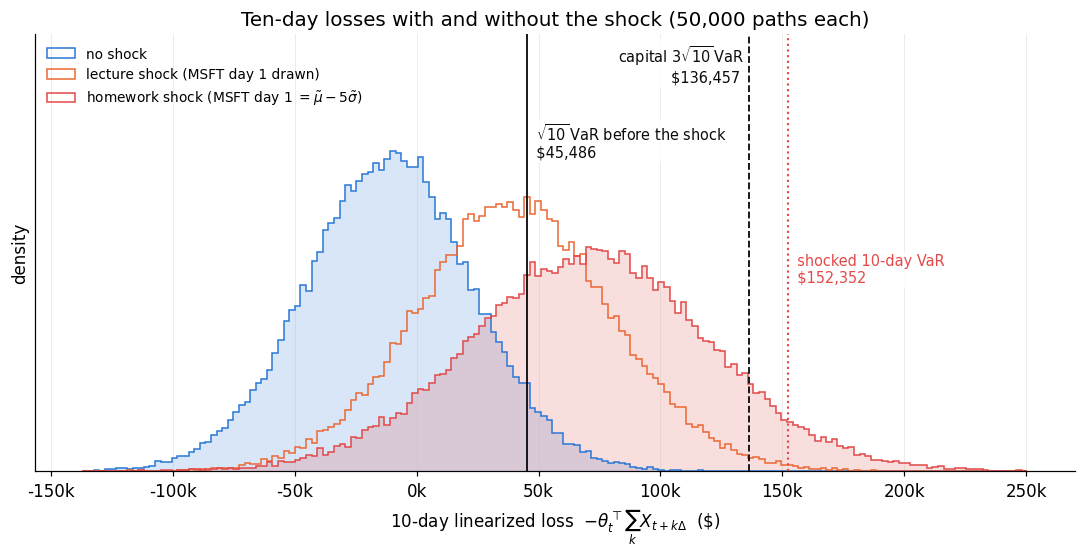

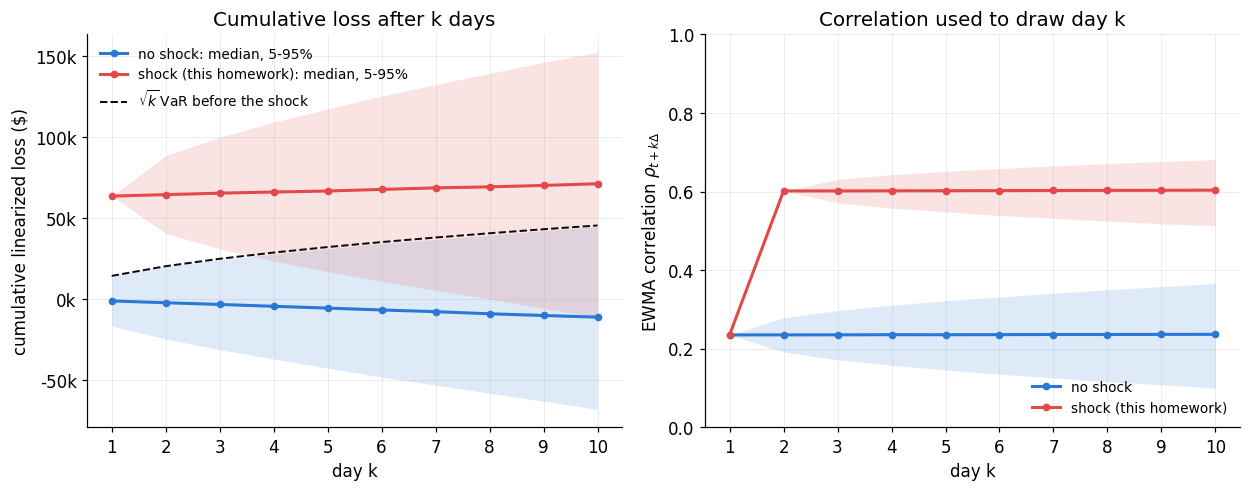

saved stress_loss_distribution.png and stress_paths.png


In [13]:
fig, ax = plt.subplots(figsize=(10, 5.2))
lo = min(np.percentile(L_BASE, 0.05), 0) - 5_000
hi = max(np.percentile(L_HW, 99.95), CAPITAL) + 10_000
bins = np.linspace(lo, hi, 170)
hkw = dict(bins=bins, density=True)
ax.hist(L_BASE, **hkw, histtype="stepfilled", color=C_BASE, alpha=0.18, lw=0)
ax.hist(L_BASE, **hkw, histtype="step", color=C_BASE, lw=1.6, label="no shock")
ax.hist(L_LECT, **hkw, histtype="step", color=C_LECT, lw=1.4, ls="--",
        label="lecture shock (MSFT day 1 drawn)")
ax.hist(L_HW, **hkw, histtype="stepfilled", color=C_SHOCK, alpha=0.18, lw=0)
ax.hist(L_HW, **hkw, histtype="step", color=C_SHOCK, lw=1.8,
        label=r"homework shock (MSFT day 1 $=\tilde\mu-5\tilde\sigma$)")
ymax = ax.get_ylim()[1] * 1.30
ax.set_ylim(0, ymax)
box = dict(fc="white", ec="none", alpha=0.85, pad=1.5)
ax.axvline(VAR_K, color=C_INK, lw=1.2, zorder=4)
ax.text(VAR_K, ymax * 0.80, r"  $\sqrt{10}\,$VaR before the shock" + "\n  " + usd(VAR_K),
        va="top", ha="left", fontsize=9.5, color=C_INK, bbox=box)
ax.axvline(CAPITAL, color=C_INK, lw=1.2, ls="--", zorder=4)
ax.text(CAPITAL, ymax * 0.98, r"capital $3\sqrt{10}\,$VaR  " + "\n" + usd(CAPITAL) + "  ",
        va="top", ha="right", fontsize=9.5, color=C_INK, bbox=box)
ax.axvline(R_HW["var"], color=C_SHOCK, lw=1.4, ls=":", zorder=4)
ax.text(R_HW["var"], ymax * 0.50, "  shocked 10-day VaR\n  " + usd(R_HW["var"]), va="top", ha="left",
        fontsize=9.5, color=C_SHOCK, bbox=box)
ax.set_xlabel(r"10-day linearized loss  $-\theta_t^{\top}\sum_k X_{t+k\Delta}$  (\$)")
ax.set_ylabel("density")
ax.set_yticks([])
ax.set_title(f"Ten-day losses with and without the shock ({M_PATHS:,} paths each)")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.legend(loc="upper left", fontsize=9, bbox_to_anchor=(0.0, 1.0))
fig.tight_layout(); fig.savefig(FIG1, bbox_inches="tight"); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6))
days = np.arange(1, K_DAYS + 1)
for cum, col, lab in ((CUM_BASE, C_BASE, "no shock"), (CUM_HW, C_SHOCK, "shock (this homework)")):
    p5, p50, p95 = np.percentile(cum, [5, 50, 95], axis=0)
    a1.fill_between(days, p5, p95, color=col, alpha=0.15, lw=0)
    a1.plot(days, p50, color=col, lw=2.0, marker="o", ms=4, label=lab + ": median, 5-95%")
a1.plot(days, np.sqrt(days) * VAR_1, color=C_INK, lw=1.3, ls="--", label=r"$\sqrt{k}\,$VaR before the shock")
a1.set_xlabel("day k"); a1.set_ylabel("cumulative linearized loss (\\$)")
a1.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
a1.set_title("Cumulative loss after k days"); a1.legend(fontsize=9, loc="upper left")
a1.set_xticks(days)
for rho, col, lab in ((RHO_BASE, C_BASE, "no shock"), (RHO_HW, C_SHOCK, "shock (this homework)")):
    p5, p50, p95 = np.percentile(rho, [5, 50, 95], axis=0)
    a2.fill_between(days, p5, p95, color=col, alpha=0.15, lw=0)
    a2.plot(days, p50, color=col, lw=2.0, marker="o", ms=4, label=lab)
a2.set_xlabel("day k"); a2.set_ylabel(r"EWMA correlation $\rho_{t+k\Delta}$")
a2.set_title("Correlation used to draw day k"); a2.set_ylim(0, 1); a2.set_xticks(days)
a2.legend(fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIG2, bbox_inches="tight"); plt.show()
print(f"saved {FIG1} and {FIG2}")

---
## 13. All numbers for the written PDF

In [14]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"[DATA]    {N_OBS} prices, {n_ret} returns, {prices.index[0].date()} -> {prices.index[-1].date()}")
print(f"[WEIGHTS] w = {W[0]:.6f}, {W[1]:.6f};  theta_t = {THETA_T[0]:,.2f}, {THETA_T[1]:,.2f}")
print(f"[STEP 1]  mu = ({MU_1[0]:.8f}, {MU_1[1]:.8f});  sigma = ({VOL_1[0]:.8f}, {VOL_1[1]:.8f});  rho = {RHO_1:.6f}")
print(f"          Sigma11 = {SIG_1[0, 0]:.10f}, Sigma12 = {SIG_1[0, 1]:.10f}, Sigma22 = {SIG_1[1, 1]:.10f}")
print(f"[STEP 2]  m = {M1:,.4f}, s = {S1:,.4f}, VaR_1 = {VAR_1:,.4f}, sqrt10 VaR = {VAR_K:,.4f}, capital = {CAPITAL:,.4f}")
print(f"[STEP 3]  x2 = {X2:.8f}, mu~ = {MU_TILDE:.8f}, sd~ = {SD_TILDE:.8f}, x1 = {X1:.8f}, day-1 loss = {LOSS_DAY1:,.4f}")
print(f"          mu_2D = ({MU_2[0]:.8f}, {MU_2[1]:.8f}); sigma_2D = ({VOL_2[0]:.8f}, {VOL_2[1]:.8f}); rho_2D = {RHO_2:.6f}")
print(f"          Sigma_2D: 11 = {SIG_2[0, 0]:.10f}, 12 = {SIG_2[0, 1]:.10f}, 22 = {SIG_2[1, 1]:.10f}")
print(f"[(a)]     mean = {R_HW['mean']:,.4f} +/- {1.96 * R_HW['se']:,.2f};  closed form {EL_HW:,.4f}")
print(f"[(b)]     VaR = {R_HW['var']:,.4f} (order stat {R_HW['j']}), band {R_HW['band'][0]:,.2f} .. {R_HW['band'][1]:,.2f}")
print(f"[(c)]     {R_HW['f_var']:.4f} %  ({R_HW['n_var']} paths)")
print(f"[(d)]     {R_HW['f_cap']:.4f} %  ({R_HW['n_cap']} paths)")
for nm, R in (("LECTURE-SHOCK", R_LECT), ("NO SHOCK", R_BASE)):
    print(f"[{nm}] mean {R['mean']:,.2f}, VaR {R['var']:,.2f}, % > VaR {R['f_var']:.3f}, % > capital {R['f_cap']:.3f}")

SUMMARY OF RESULTS
[DATA]    1259 prices, 1258 returns, 2011-09-01 -> 2016-09-01
[WEIGHTS] w = 0.438303, 0.561697;  theta_t = 438,303.32, 561,696.68
[STEP 1]  mu = (0.00125025, 0.00106069);  sigma = (0.01139724, 0.01232281);  rho = 0.235013
          Sigma11 = 0.0001298971, Sigma12 = 0.0000330066, Sigma22 = 0.0001518517
[STEP 2]  m = -1,143.7758, s = 9,440.1389, VaR_1 = 14,383.8709, sqrt10 VaR = 45,485.7935, capital = 136,457.3804
[STEP 3]  x2 = -0.06055336, mu~ = -0.01214224, sd~ = 0.01107803, x1 = -0.06753239, day-1 loss = 63,612.2939
          mu_2D = (-0.00081323, -0.00078773); sigma_2D = (0.01636862, 0.01616122); rho_2D = 0.601639
          Sigma_2D: 11 = 0.0002679317, 12 = 0.0001591557, 22 = 0.0002611849
[(a)]     mean = 70,970.4700 +/- 435.21;  closed form 70,802.4503
[(b)]     VaR = 152,352.0554 (order stat 47500), band 151,325.07 .. 153,415.92
[(c)]     69.8660 %  (34933 paths)
[(d)]     9.1000 %  (4550 paths)
[LECTURE-SHOCK] mean 40,035.76, VaR 106,265.10, % > VaR 44.410, % >

---
## 14. Self-checks

In [15]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("data: first and last dates as specified, no gaps in the table", str(prices.index[0].date()) == FIRST_DAY
      and str(prices.index[-1].date()) == LAST_DAY and prices.notna().all().all())
# EWMA with zero start = explicit exponentially weighted sum
wts = (1 - LAM) * LAM ** np.arange(n_ret - 1, -1, -1)
check("EWMA mean equals (1 - lambda) sum lambda^(n-j) X_j", np.allclose(MU_1, wts @ X_HIST, rtol=0, atol=1e-14))
check("EWMA covariance is symmetric positive definite", np.allclose(SIG_1, SIG_1.T) and np.all(np.linalg.eigvalsh(SIG_1) > 0))
# one-day VaR by simulation (day 1 of the no-shock experiment) agrees with the formula
l1 = -(day1_base @ THETA_T); b1 = quantile_band(l1)
check("one-day normal VaR formula inside the simulated order-statistic band", b1[0] <= VAR_1 <= b1[1])
check("x1 = mu1 - 5 sigma1 (rho + sqrt(1 - rho^2))",
      abs(X1 - (MU_1[0] - 5 * VOL_1[0] * (RHO_1 + np.sqrt(1 - RHO_1 ** 2)))) < 1e-14)
check("Sigma after the shock is positive definite", np.all(np.linalg.eigvalsh(SIG_2) > 0))
check("(a) simulated mean within 4 standard errors of the closed form", abs(R_HW["mean"] - EL_HW) < 4 * R_HW["se"])
check("no shock: simulated mean within 4 s.e. of -K theta' mu", abs(R_BASE["mean"] - EL_BASE) < 4 * R_BASE["se"])
check("lecture shock: simulated mean within 4 s.e. of the closed form", abs(R_LECT["mean"] - EL_LECT) < 4 * R_LECT["se"])
check("(b) VaR is the 47,500th smallest of 50,000 losses", R_HW["j"] == 47_500
      and R_HW["var"] == np.sort(L_HW)[47_499])
check("(c), (d) frequencies equal 100/M x counts", abs(R_HW["f_var"] - 100 * np.sum(L_HW > VAR_K) / M_PATHS) < 1e-12
      and abs(R_HW["f_cap"] - 100 * np.sum(L_HW > CAPITAL) / M_PATHS) < 1e-12)
# independent per-path loop with numpy's Cholesky, on the first 1,000 paths
n_chk = 1_000; L_chk = np.empty(n_chk)
for m in range(n_chk):
    mu_m, S_m = ewma_update(MU_1, SIG_1, X_SHOCK); tot = X_SHOCK.copy()
    for k in range(1, K_DAYS):
        x = mu_m + np.linalg.cholesky(S_m) @ ZS[m, k]
        tot = tot + x
        if k < K_DAYS - 1:
            dev = x - mu_m
            mu_m = LAM * mu_m + (1 - LAM) * x
            S_m = THETA * S_m + (1 - THETA) * np.outer(dev, dev)
    L_chk[m] = -THETA_T @ tot
check("independent per-path loop reproduces the vectorised losses", np.allclose(L_chk, L_HW[:n_chk], rtol=0, atol=1e-6))
check("lecture version: every drawn day-1 MSFT return lies above x1 (smaller day-1 loss)", (day1_lect[:, 0] > X1).all())
check("the homework's shock gives the larger mean loss and VaR", R_HW["mean"] > R_LECT["mean"] and R_HW["var"] > R_LECT["var"])
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  data: first and last dates as specified, no gaps in the table
  [PASS]  EWMA mean equals (1 - lambda) sum lambda^(n-j) X_j
  [PASS]  EWMA covariance is symmetric positive definite
  [PASS]  one-day normal VaR formula inside the simulated order-statistic band
  [PASS]  x1 = mu1 - 5 sigma1 (rho + sqrt(1 - rho^2))
  [PASS]  Sigma after the shock is positive definite
  [PASS]  (a) simulated mean within 4 standard errors of the closed form
  [PASS]  no shock: simulated mean within 4 s.e. of -K theta' mu
  [PASS]  lecture shock: simulated mean within 4 s.e. of the closed form
  [PASS]  (b) VaR is the 47,500th smallest of 50,000 losses
  [PASS]  (c), (d) frequencies equal 100/M x counts
  [PASS]  independent per-path loop reproduces the vectorised losses
  [PASS]  lecture version: every drawn day-1 MSFT return lies above x1 (smaller day-1 loss)
  [PASS]  the homework's shock gives the larger mean loss and VaR
  [PASS]  figures written

ALL CHECKS PASSED
